In [57]:
# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [58]:
# Step 2: Import Machine Learning Tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, f1_score
from sklearn.metrics import precision_score, recall_score, brier_score_loss
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
import shap

In [59]:
# Step 3: Load the Dataset
data = pd.read_csv('post natal data.csv')
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

Rows: 1503
Columns: 11


In [60]:
# Step 4: Preview First 5 Rows
data.head()

,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [61]:
# Step 5: Check Column Names
print(data.columns.tolist())

['Timestamp', 'Age', 'Feeling sad or Tearful', 'Irritable towards baby & partner', 'Trouble sleeping at night', 'Problems concentrating or making decision', 'Overeating or loss of appetite', 'Feeling anxious', 'Feeling of guilt', 'Problems of bonding with baby', 'Suicide attempt']


In [62]:
# Step 6: Check for Missing Values
print(data.isnull().sum())

Timestamp                                     0
Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling anxious                               0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
dtype: int64


In [63]:
# Step 7: Check for Duplicate Rows
# Duplicates cause fake high accuracy (data leakage)
temp = data.drop(columns=['Timestamp'])
total     = len(temp)
unique    = temp.drop_duplicates().shape[0]
duplicate = total - unique

print("Total rows    :", total)
print("Unique rows   :", unique)
print("Duplicate rows:", duplicate)

Total rows    : 1503
Unique rows   : 326
Duplicate rows: 1177


In [64]:
# Step 8: Remove Timestamp Column
# Timestamp is just a recording time — not useful for prediction
data = data.drop(columns=['Timestamp'])
print("Shape after dropping Timestamp:", data.shape)

Shape after dropping Timestamp: (1503, 10)


In [65]:
# Step 9: Fill Missing Values with Most Common Value (Mode)
for col in data.columns:
    if data[col].isnull().sum() > 0:
        most_common = data[col].mode()[0]
        data[col]   = data[col].fillna(most_common)
        print("Filled:", col, "with:", most_common)

Filled: Irritable towards baby & partner with: Yes
Filled: Problems concentrating or making decision with: No
Filled: Feeling of guilt with: No


In [66]:
# Step 10: Remove Duplicate Rows
rows_before = len(data)
data        = data.drop_duplicates().reset_index(drop=True)
rows_after  = len(data)

print("Rows before:", rows_before)
print("Rows after :", rows_after)
print("Removed    :", rows_before - rows_after)

Rows before: 1503
Rows after : 326
Removed    : 1177


In [67]:
# Step 11: Encode Text Values to Numbers
# Machine learning needs numbers, not text

age_map      = {'25-30':0, '30-35':1, '35-40':2, '40-45':3, '45-50':4}
symptom_map  = {'No':0, 'Sometimes':1, 'Yes':2}
sleep_map    = {'No':0, 'Two or more days a week':1, 'Yes':2}
concen_map   = {'No':0, 'Often':1, 'Yes':2}
appetite_map = {'Not at all':0, 'No':1, 'Yes':2}
guilt_map    = {'No':0, 'Maybe':1, 'Yes':2}
suicide_map  = {'No':0, 'Not interested to say':1, 'Yes':2}
target_map   = {'No':0, 'Yes':1}

data['Age']                                       = data['Age'].map(age_map)
data['Feeling sad or Tearful']                    = data['Feeling sad or Tearful'].map(symptom_map)
data['Irritable towards baby & partner']          = data['Irritable towards baby & partner'].map(symptom_map)
data['Trouble sleeping at night']                 = data['Trouble sleeping at night'].map(sleep_map)
data['Problems concentrating or making decision'] = data['Problems concentrating or making decision'].map(concen_map)
data['Overeating or loss of appetite']            = data['Overeating or loss of appetite'].map(appetite_map)
data['Feeling of guilt']                          = data['Feeling of guilt'].map(guilt_map)
data['Problems of bonding with baby']             = data['Problems of bonding with baby'].map(symptom_map)
data['Suicide attempt']                           = data['Suicide attempt'].map(suicide_map)
data['Feeling anxious']                           = data['Feeling anxious'].map(target_map)

print("Encoding done.")
data.head()

Encoding done.


,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,2,1,2,2,1,0,2,2
1,3,2,0,0,2,2,0,2,2,0
2,2,2,0,2,2,2,1,0,1,0
3,2,2,2,2,2,1,1,1,0,0
4,3,2,0,1,2,1,1,0,2,0


In [68]:
# Step 12: Count Target Classes
# 0 = No Anxiety   1 = High Anxiety
no_anxiety   = (data['Feeling anxious'] == 0).sum()
high_anxiety = (data['Feeling anxious'] == 1).sum()
total        = len(data)

print("No Anxiety  :", no_anxiety,  f"({no_anxiety/total*100:.1f}%)")
print("High Anxiety:", high_anxiety, f"({high_anxiety/total*100:.1f}%)")
print("Baseline accuracy (always guess majority):", round(max(no_anxiety, high_anxiety)/total*100, 1), "%")

No Anxiety  : 137 (42.0%)
High Anxiety: 189 (58.0%)
Baseline accuracy (always guess majority): 58.0 %


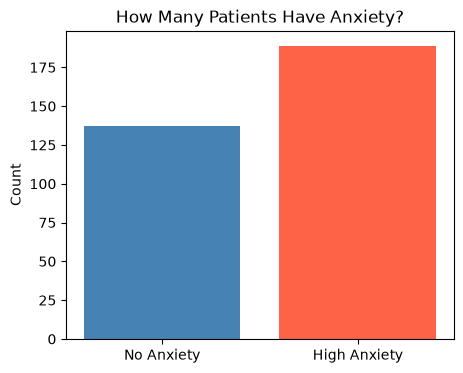

In [69]:
# Step 13: Bar Chart — Target Distribution
plt.figure(figsize=(5, 4))
plt.bar(['No Anxiety', 'High Anxiety'], [no_anxiety, high_anxiety], color=['steelblue', 'tomato'])
plt.title('How Many Patients Have Anxiety?')
plt.ylabel('Count')
plt.savefig('target_distribution.png', dpi=100)
plt.show()

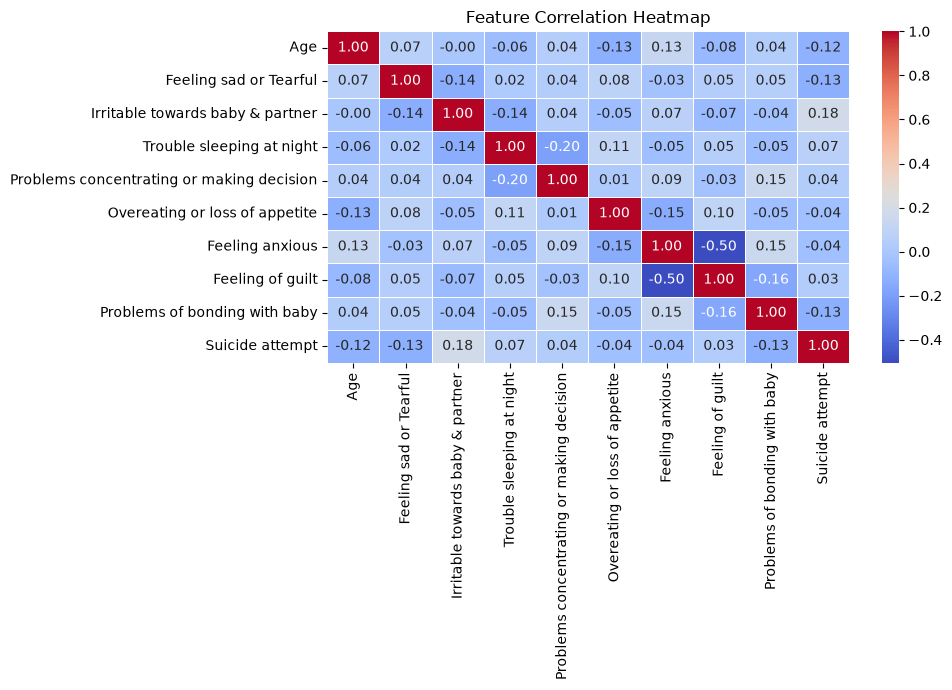

In [70]:
# Step 14: Correlation Heatmap
# Shows which features are related to each other
plt.figure(figsize=(10, 7))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=100)
plt.show()

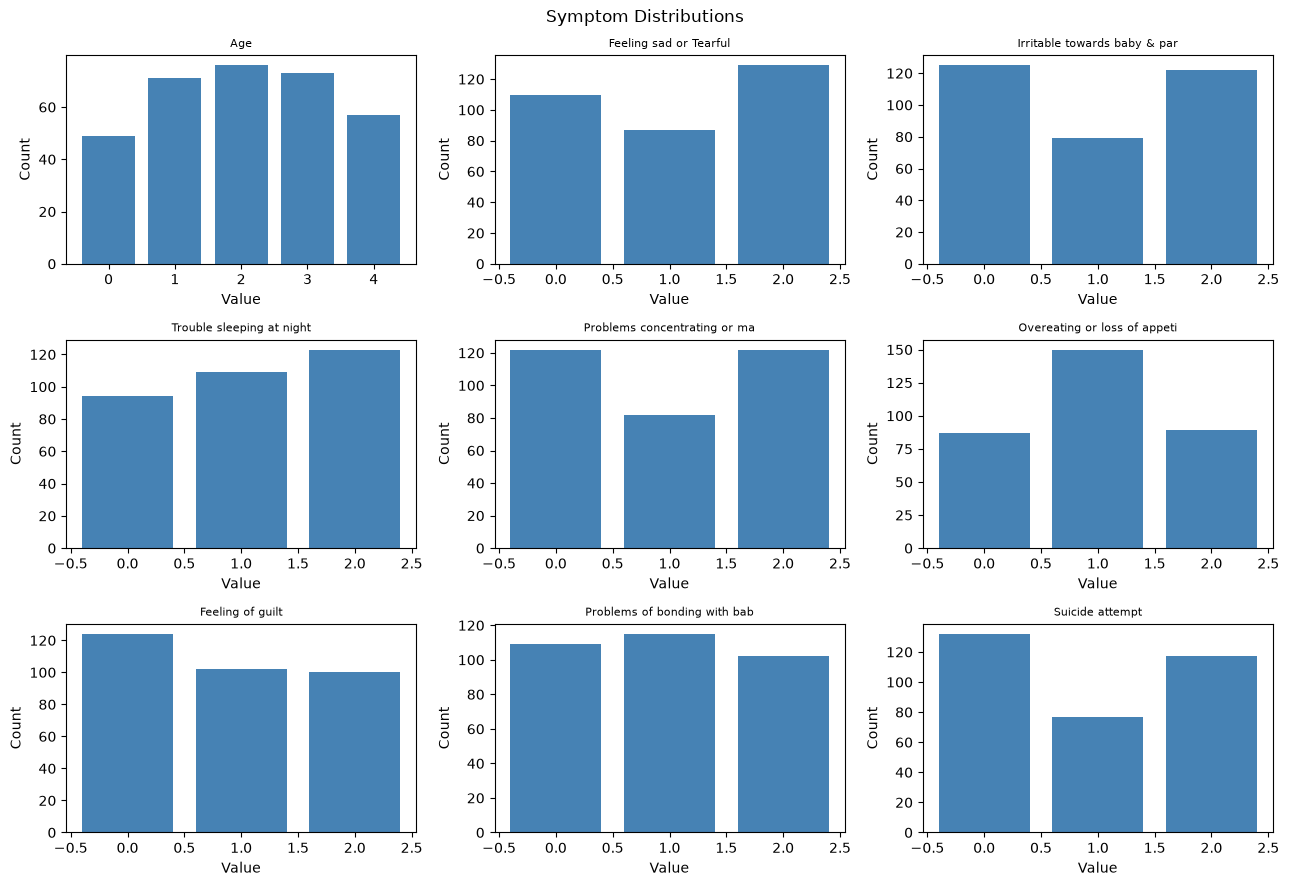

In [71]:
# Step 15: Bar Chart — Each Symptom Distribution
feature_cols = [c for c in data.columns if c != 'Feeling anxious']

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for i, col in enumerate(feature_cols):
    ax = axes[i // 3][i % 3]
    counts = data[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color='steelblue')
    ax.set_title(col[:28], fontsize=8)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

plt.suptitle('Symptom Distributions', fontsize=12)
plt.tight_layout()
plt.savefig('symptom_distributions.png', dpi=100)
plt.show()

In [72]:
# Step 16: Create New Features (Feature Engineering)
# These new features help the model learn better patterns

symptom_cols = [
    'Feeling sad or Tearful',
    'Irritable towards baby & partner',
    'Trouble sleeping at night',
    'Problems concentrating or making decision',
    'Overeating or loss of appetite',
    'Feeling of guilt',
    'Problems of bonding with baby',
    'Suicide attempt',
]

# Total score: sum of all symptoms
data['total_symptom_score'] = data[symptom_cols].sum(axis=1)

# Count how many symptoms are severe (value = 2)
data['severe_symptom_count'] = (data[symptom_cols] == 2).sum(axis=1)

# Count how many symptoms are mild (value = 1)
data['mild_symptom_count'] = (data[symptom_cols] == 1).sum(axis=1)

# Interaction: multiply related symptoms together
data['sleep_sadness']   = data['Trouble sleeping at night'] * data['Feeling sad or Tearful']
data['guilt_bonding']   = data['Feeling of guilt'] * data['Problems of bonding with baby']
data['irritable_sleep'] = data['Irritable towards baby & partner'] * data['Trouble sleeping at night']

print("New features created. Total features now:", data.shape[1] - 1)

New features created. Total features now: 15


In [73]:
# Step 17: Separate Features (X) and Target (y)
X = data.drop(columns=['Feeling anxious'])   # input features
y = data['Feeling anxious']                  # what we want to predict

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (326, 15)
y shape: (326,)


In [74]:
# Step 18: Split Data — 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y        # keeps class ratio same in both sets
)

print("Training rows :", len(X_train))
print("Testing  rows :", len(X_test))

Training rows : 260
Testing  rows : 66


In [75]:
# Step 19: Check for Data Leakage
# If training and testing rows overlap, accuracy will be fake

train_tuples = set(map(tuple, X_train.values))
test_tuples  = set(map(tuple, X_test.values))
overlap      = len(train_tuples & test_tuples)

print("Overlap between train and test:", overlap)
print("(Should be 0 — no leakage)")

Overlap between train and test: 0
(Should be 0 — no leakage)


In [76]:
# Step 20: Apply SMOTE — Balance the Training Classes
# SMOTE creates synthetic samples for the smaller class
# Only apply on TRAINING data — never on test data

sm = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

print("Before SMOTE — class counts:")
print(y_train.value_counts().to_dict())

print("After  SMOTE — class counts:")
print(pd.Series(y_train_sm).value_counts().to_dict())

Before SMOTE — class counts:
{1: 151, 0: 109}
After  SMOTE — class counts:
{1: 151, 0: 151}


In [77]:
# Step 21: Compute Class Weights
# Another way to handle imbalance: give more weight to the minority class
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {0: round(weights[0], 3), 1: round(weights[1], 3)}
print("Class weights:", class_weight_dict)

Class weights: {0: np.float64(1.193), 1: np.float64(0.861)}


In [78]:
# Step 22: Train Model 1 — Logistic Regression
# Pipeline = Scale data first, then train model

lr_params = {'model__C': [0.01, 0.1, 1.0, 10.0]}

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

lr_search = GridSearchCV(lr_pipeline, lr_params, cv=5, scoring='roc_auc', n_jobs=-1)
lr_search.fit(X_train_sm, y_train_sm)

lr_model = lr_search.best_estimator_
print("Best setting found:", lr_search.best_params_)

Best setting found: {'model__C': 10.0}


In [79]:
# Step 23: Logistic Regression — Accuracy Results
lr_preds      = lr_model.predict(X_test)
lr_train_acc  = accuracy_score(y_train_sm, lr_model.predict(X_train_sm)) * 100
lr_test_acc   = accuracy_score(y_test, lr_preds) * 100
lr_balanced   = balanced_accuracy_score(y_test, lr_preds) * 100

print("Logistic Regression:")
print(f"  Train Accuracy    : {lr_train_acc:.1f}%")
print(f"  Test  Accuracy    : {lr_test_acc:.1f}%")
print(f"  Balanced Accuracy : {lr_balanced:.1f}%")

Logistic Regression:
  Train Accuracy    : 77.5%
  Test  Accuracy    : 80.3%
  Balanced Accuracy : 77.7%


In [80]:
# Step 24: Logistic Regression — Detailed Report
print(classification_report(y_test, lr_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.89      0.61      0.72        28
High Anxiety       0.77      0.95      0.85        38

    accuracy                           0.80        66
   macro avg       0.83      0.78      0.79        66
weighted avg       0.82      0.80      0.79        66



In [81]:
# Step 25: Train Model 2 — SVM (Support Vector Machine)
svm_params = {
    'model__C':     [0.1, 1.0, 10.0],
    'model__gamma': ['scale', 'auto'],
}

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42))
])

svm_search = GridSearchCV(svm_pipeline, svm_params, cv=5, scoring='roc_auc', n_jobs=-1)
svm_search.fit(X_train_sm, y_train_sm)

svm_model = svm_search.best_estimator_
print("Best setting found:", svm_search.best_params_)

Best setting found: {'model__C': 1.0, 'model__gamma': 'scale'}


In [82]:
# Step 26: SVM — Accuracy Results
svm_preds     = svm_model.predict(X_test)
svm_train_acc = accuracy_score(y_train_sm, svm_model.predict(X_train_sm)) * 100
svm_test_acc  = accuracy_score(y_test, svm_preds) * 100
svm_balanced  = balanced_accuracy_score(y_test, svm_preds) * 100

print("SVM:")
print(f"  Train Accuracy    : {svm_train_acc:.1f}%")
print(f"  Test  Accuracy    : {svm_test_acc:.1f}%")
print(f"  Balanced Accuracy : {svm_balanced:.1f}%")

SVM:
  Train Accuracy    : 86.1%
  Test  Accuracy    : 75.8%
  Balanced Accuracy : 75.2%


In [83]:
# Step 27: SVM — Detailed Report
print(classification_report(y_test, svm_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.71      0.71      0.71        28
High Anxiety       0.79      0.79      0.79        38

    accuracy                           0.76        66
   macro avg       0.75      0.75      0.75        66
weighted avg       0.76      0.76      0.76        66



In [84]:
# Step 28: Train Model 3 — Random Forest
rf_params = {
    'n_estimators':     [100, 200],
    'max_depth':        [3, 4, 5],
    'min_samples_leaf': [5, 6, 8],
    'max_features':     ['sqrt'],
}

rf_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    rf_params, cv=5, scoring='roc_auc', n_jobs=-1
)
rf_search.fit(X_train_sm, y_train_sm)

rf_model = rf_search.best_estimator_
print("Best setting found:", rf_search.best_params_)

Best setting found: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 100}


In [85]:
# Step 29: Random Forest — Accuracy Results
rf_preds     = rf_model.predict(X_test)
rf_train_acc = accuracy_score(y_train_sm, rf_model.predict(X_train_sm)) * 100
rf_test_acc  = accuracy_score(y_test, rf_preds) * 100
rf_balanced  = balanced_accuracy_score(y_test, rf_preds) * 100

print("Random Forest:")
print(f"  Train Accuracy    : {rf_train_acc:.1f}%")
print(f"  Test  Accuracy    : {rf_test_acc:.1f}%")
print(f"  Balanced Accuracy : {rf_balanced:.1f}%")

Random Forest:
  Train Accuracy    : 83.4%
  Test  Accuracy    : 75.8%
  Balanced Accuracy : 75.7%


In [86]:
# Step 30: Random Forest — Detailed Report
print(classification_report(y_test, rf_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.70      0.75      0.72        28
High Anxiety       0.81      0.76      0.78        38

    accuracy                           0.76        66
   macro avg       0.75      0.76      0.75        66
weighted avg       0.76      0.76      0.76        66



In [87]:
# Step 31: Train Model 4 — Gradient Boosting
gb_params = {
    'n_estimators':     [100, 200, 300],
    'learning_rate':    [0.01, 0.05, 0.1],
    'max_depth':        [2, 3],
    'min_samples_leaf': [3, 5],
}

gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params, cv=5, scoring='roc_auc', n_jobs=-1
)
gb_search.fit(X_train_sm, y_train_sm)

gb_model = gb_search.best_estimator_
print("Best setting found:", gb_search.best_params_)

Best setting found: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 3, 'n_estimators': 200}


In [88]:
# Step 32: Gradient Boosting — Accuracy Results
gb_preds     = gb_model.predict(X_test)
gb_train_acc = accuracy_score(y_train_sm, gb_model.predict(X_train_sm)) * 100
gb_test_acc  = accuracy_score(y_test, gb_preds) * 100
gb_balanced  = balanced_accuracy_score(y_test, gb_preds) * 100

print("Gradient Boosting:")
print(f"  Train Accuracy    : {gb_train_acc:.1f}%")
print(f"  Test  Accuracy    : {gb_test_acc:.1f}%")
print(f"  Balanced Accuracy : {gb_balanced:.1f}%")

Gradient Boosting:
  Train Accuracy    : 89.7%
  Test  Accuracy    : 71.2%
  Balanced Accuracy : 69.4%


In [89]:
# Step 33: Gradient Boosting — Detailed Report
print(classification_report(y_test, gb_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.70      0.57      0.63        28
High Anxiety       0.72      0.82      0.77        38

    accuracy                           0.71        66
   macro avg       0.71      0.69      0.70        66
weighted avg       0.71      0.71      0.71        66



In [90]:
# Step 34: Train Model 5 — Ensemble (Combines All 4 Models)
# Soft voting = each model votes using its probabilities, then average

ensemble_model = VotingClassifier(
    estimators=[
        ('lr',  lr_model),
        ('svm', svm_model),
        ('rf',  rf_model),
        ('gb',  gb_model),
    ],
    voting='soft'
)
ensemble_model.fit(X_train_sm, y_train_sm)
print("Ensemble model trained.")

Ensemble model trained.


In [91]:
# Step 35: Ensemble — Accuracy Results
ens_preds     = ensemble_model.predict(X_test)
ens_train_acc = accuracy_score(y_train_sm, ensemble_model.predict(X_train_sm)) * 100
ens_test_acc  = accuracy_score(y_test, ens_preds) * 100
ens_balanced  = balanced_accuracy_score(y_test, ens_preds) * 100

print("Ensemble:")
print(f"  Train Accuracy    : {ens_train_acc:.1f}%")
print(f"  Test  Accuracy    : {ens_test_acc:.1f}%")
print(f"  Balanced Accuracy : {ens_balanced:.1f}%")

Ensemble:
  Train Accuracy    : 86.4%
  Test  Accuracy    : 81.8%
  Balanced Accuracy : 80.5%


In [92]:
# Step 36: Ensemble — Detailed Report
print(classification_report(y_test, ens_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.83      0.71      0.77        28
High Anxiety       0.81      0.89      0.85        38

    accuracy                           0.82        66
   macro avg       0.82      0.80      0.81        66
weighted avg       0.82      0.82      0.82        66



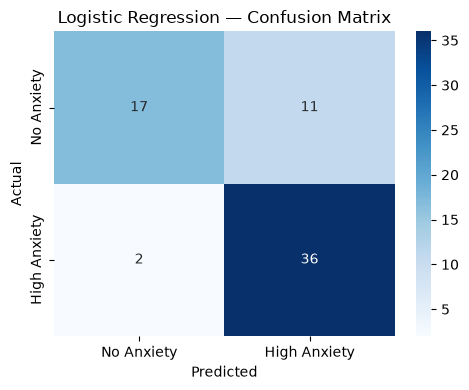

In [93]:
# Step 37: Confusion Matrix — Logistic Regression
cm = confusion_matrix(y_test, lr_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cm_lr.png', dpi=100)
plt.show()

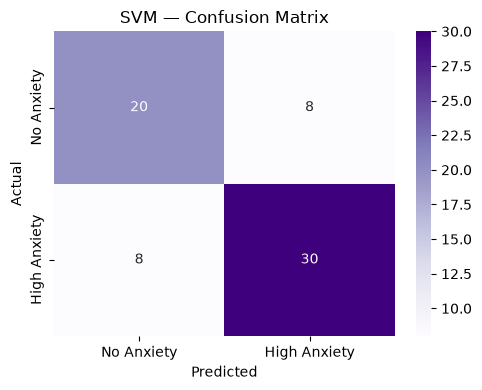

In [94]:
# Step 38: Confusion Matrix — SVM
cm = confusion_matrix(y_test, svm_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('SVM — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cm_svm.png', dpi=100)
plt.show()

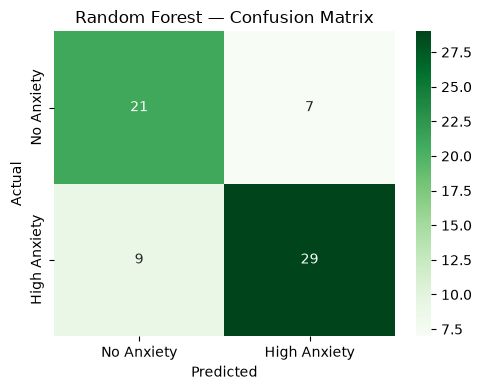

In [95]:
# Step 39: Confusion Matrix — Random Forest
cm = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Random Forest — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cm_rf.png', dpi=100)
plt.show()

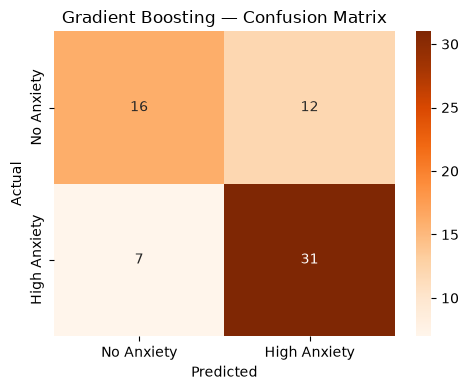

In [96]:
# Step 40: Confusion Matrix — Gradient Boosting
cm = confusion_matrix(y_test, gb_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Gradient Boosting — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cm_gb.png', dpi=100)
plt.show()

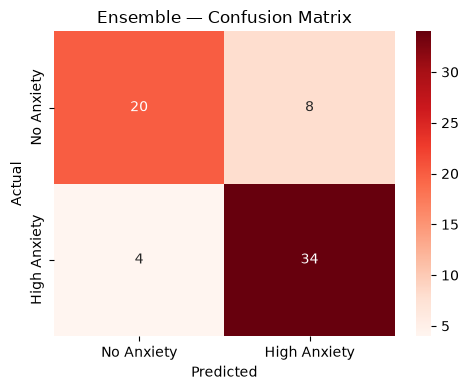

In [97]:
# Step 41: Confusion Matrix — Ensemble
cm = confusion_matrix(y_test, ens_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Ensemble — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cm_ensemble.png', dpi=100)
plt.show()

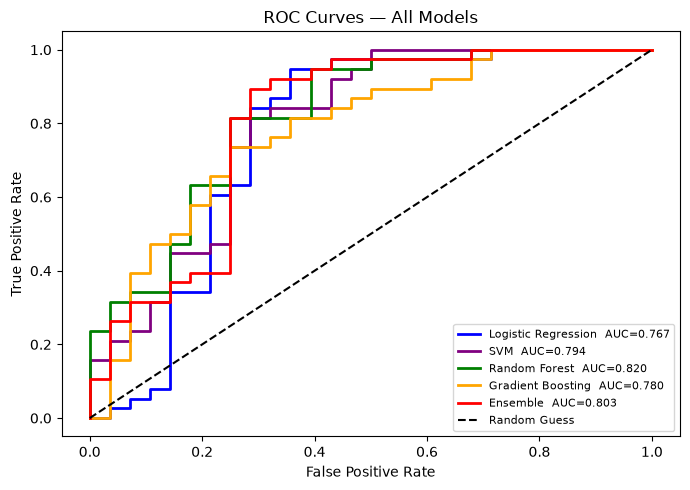

In [98]:
# Step 42: ROC Curves — All Models
# AUC closer to 1.0 = better model

plt.figure(figsize=(7, 5))

for model, preds, name, color in [
    (lr_model,       lr_preds,  'Logistic Regression', 'blue'),
    (svm_model,      svm_preds, 'SVM',                 'purple'),
    (rf_model,       rf_preds,  'Random Forest',        'green'),
    (gb_model,       gb_preds,  'Gradient Boosting',    'orange'),
    (ensemble_model, ens_preds, 'Ensemble',              'red'),
]:
    prob       = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_score  = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name}  AUC={auc_score:.3f}', color=color, lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=100)
plt.show()

In [99]:
# Step 43: 10-Fold Cross Validation — All Models
# More reliable than a single test set

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print("10-Fold Cross-Validation AUC:")
for model, name in [
    (lr_model,       'Logistic Regression'),
    (svm_model,      'SVM'),
    (rf_model,       'Random Forest'),
    (gb_model,       'Gradient Boosting'),
    (ensemble_model, 'Ensemble'),
]:
    scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc') * 100
    mean   = scores.mean()
    std    = scores.std()
    ci_low = mean - 1.96 * std
    ci_hi  = mean + 1.96 * std
    print(f"  {name:<25}: {mean:.1f}% +/- {std:.1f}%  (95% CI: {ci_low:.1f}% - {ci_hi:.1f}%)")

10-Fold Cross-Validation AUC:
  Logistic Regression      : 77.4% +/- 7.0%  (95% CI: 63.7% - 91.1%)
  SVM                      : 80.1% +/- 6.5%  (95% CI: 67.3% - 92.9%)
  Random Forest            : 80.9% +/- 6.3%  (95% CI: 68.6% - 93.3%)
  Gradient Boosting        : 78.4% +/- 4.6%  (95% CI: 69.5% - 87.3%)
  Ensemble                 : 80.3% +/- 5.6%  (95% CI: 69.3% - 91.3%)


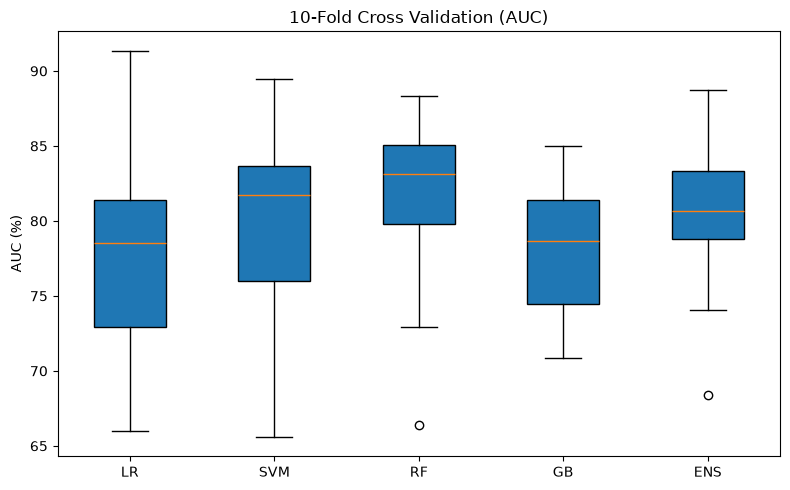

In [100]:
# Step 44: Cross Validation Box Plot
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

lr_scores  = cross_val_score(lr_model,       X, y, cv=cv, scoring='roc_auc') * 100
svm_scores = cross_val_score(svm_model,      X, y, cv=cv, scoring='roc_auc') * 100
rf_scores  = cross_val_score(rf_model,       X, y, cv=cv, scoring='roc_auc') * 100
gb_scores  = cross_val_score(gb_model,       X, y, cv=cv, scoring='roc_auc') * 100
ens_scores = cross_val_score(ensemble_model, X, y, cv=cv, scoring='roc_auc') * 100

plt.figure(figsize=(8, 5))
plt.boxplot(
    [lr_scores, svm_scores, rf_scores, gb_scores, ens_scores],
    tick_labels=['LR', 'SVM', 'RF', 'GB', 'ENS'],
    patch_artist=True
)
plt.title('10-Fold Cross Validation (AUC)')
plt.ylabel('AUC (%)')
plt.tight_layout()
plt.savefig('cv_boxplot.png', dpi=100)
plt.show()

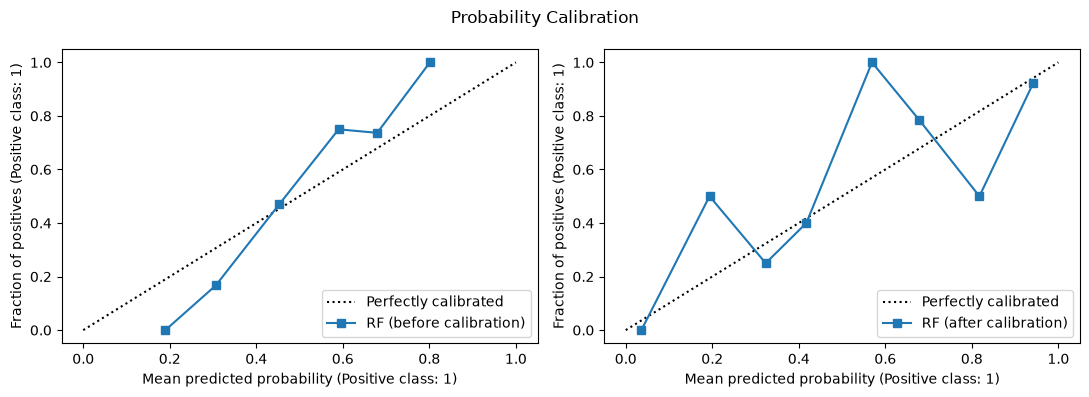

In [101]:
# Step 45: Calibration Curve — How Trustworthy Are the Probabilities?
cal_rf = CalibratedClassifierCV(rf_model, method='isotonic', cv=5)
cal_rf.fit(X_train_sm, y_train_sm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
CalibrationDisplay.from_estimator(rf_model, X_test, y_test, n_bins=8, ax=axes[0], name='RF (before calibration)')
CalibrationDisplay.from_estimator(cal_rf,   X_test, y_test, n_bins=8, ax=axes[1], name='RF (after calibration)')
plt.suptitle('Probability Calibration')
plt.tight_layout()
plt.savefig('calibration_curves.png', dpi=100)
plt.show()

In [102]:
# Step 46: Brier Score — Measures Probability Quality
# Lower = better. Score of 0.25 = random guessing.

print("Brier Score (lower is better):")
for model, name in [
    (lr_model,       'Logistic Regression'),
    (svm_model,      'SVM'),
    (rf_model,       'Random Forest'),
    (gb_model,       'Gradient Boosting'),
    (ensemble_model, 'Ensemble'),
]:
    prob  = model.predict_proba(X_test)[:, 1]
    score = brier_score_loss(y_test, prob)
    print(f"  {name:<25}: {score:.4f}")

Brier Score (lower is better):
  Logistic Regression      : 0.1760
  SVM                      : 0.1745
  Random Forest            : 0.1740
  Gradient Boosting        : 0.1930
  Ensemble                 : 0.1677


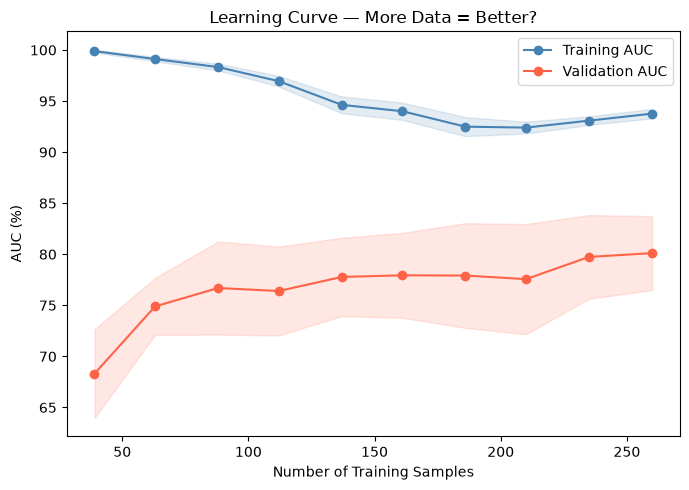

Max validation AUC at full data: 80.1%


In [103]:
# Step 47: Learning Curve — Does More Data Help?
train_sizes, train_scores, val_scores = learning_curve(
    ensemble_model, X, y,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='roc_auc',
    train_sizes=np.linspace(0.15, 1.0, 10),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1) * 100
val_mean   = val_scores.mean(axis=1)   * 100
train_std  = train_scores.std(axis=1)  * 100
val_std    = val_scores.std(axis=1)    * 100

plt.figure(figsize=(7, 5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Training AUC')
plt.plot(train_sizes, val_mean,   'o-', color='tomato',    label='Validation AUC')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')
plt.fill_between(train_sizes, val_mean   - val_std,   val_mean   + val_std,   alpha=0.15, color='tomato')
plt.xlabel('Number of Training Samples')
plt.ylabel('AUC (%)')
plt.title('Learning Curve — More Data = Better?')
plt.legend()
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=100)
plt.show()

print(f"Max validation AUC at full data: {val_mean[-1]:.1f}%")

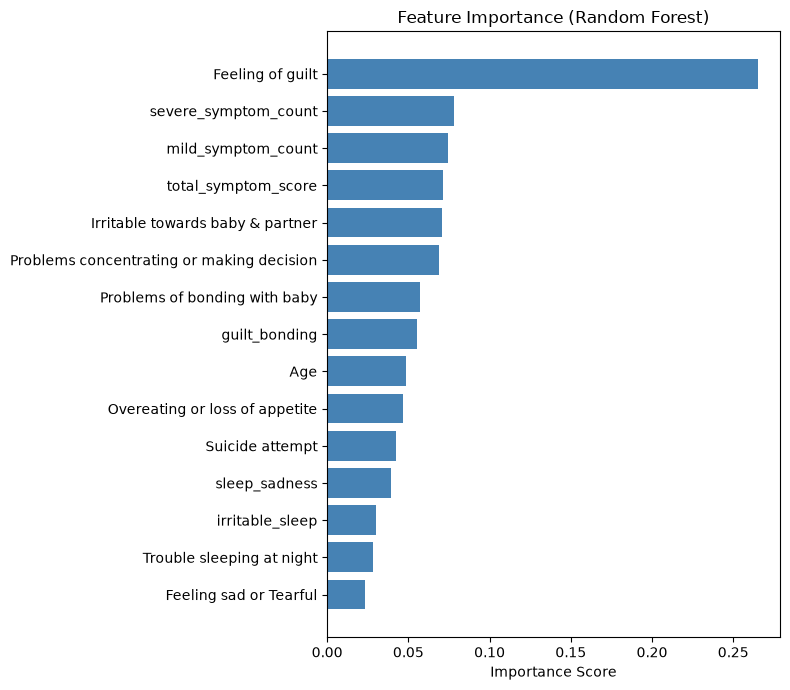

In [104]:
# Step 48: Feature Importance — Which Symptoms Matter Most?
importance_values = rf_model.feature_importances_
feature_names     = X.columns.tolist()

importance_df = pd.DataFrame({
    'Feature'    : feature_names,
    'Importance' : importance_values
})
importance_df = importance_df.sort_values('Importance', ascending=True)

plt.figure(figsize=(8, 7))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
plt.xlabel('Importance Score')
plt.title('Feature Importance (Random Forest)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=100)
plt.show()

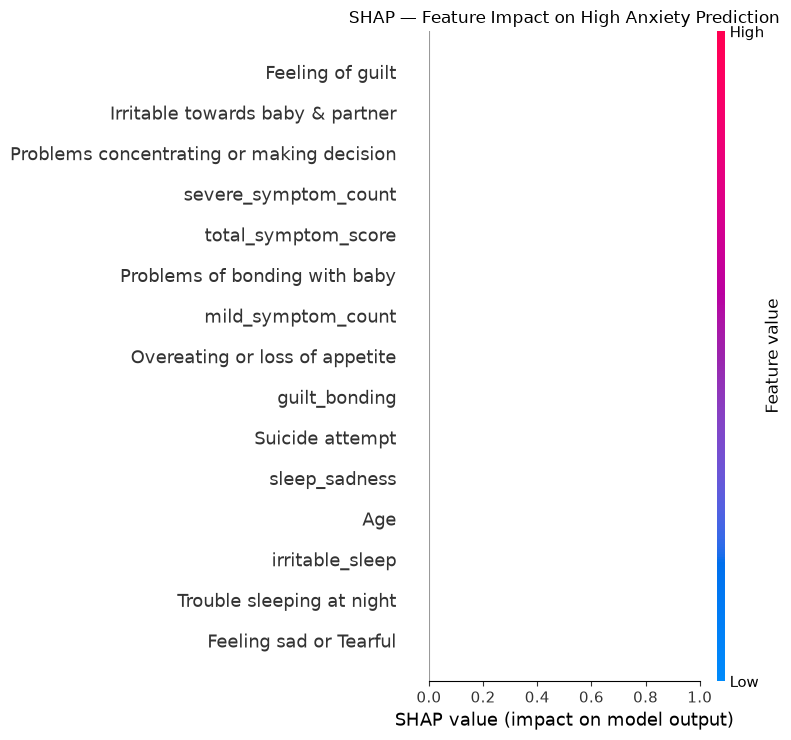

In [105]:
# Step 49: SHAP Values — How Each Feature Affects Each Patient
# SHAP is the modern standard for explaining AI predictions

explainer   = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# For binary classification: index [1] = High Anxiety class
if isinstance(shap_values, list):
    shap_pos = shap_values[1]
else:
    shap_pos = shap_values[:, :, 1]

plt.figure()
shap.summary_plot(shap_pos, X_test, plot_type='beeswarm', show=False, max_display=15)
plt.title('SHAP — Feature Impact on High Anxiety Prediction')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=100, bbox_inches='tight')
plt.show()

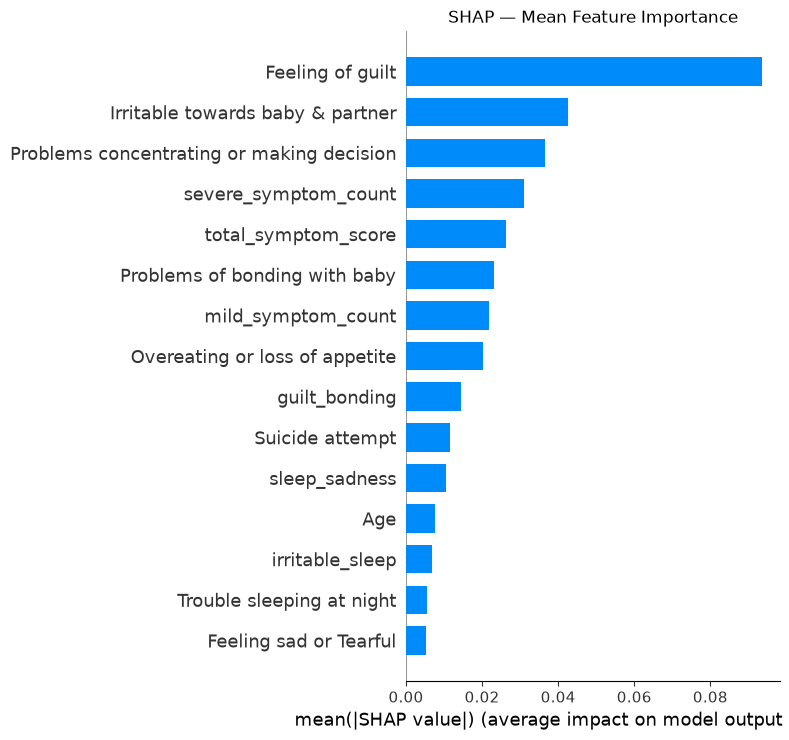

In [106]:
# Step 50: SHAP Bar Chart — Average Feature Impact
plt.figure()
shap.summary_plot(shap_pos, X_test, plot_type='bar', show=False, max_display=15)
plt.title('SHAP — Mean Feature Importance')
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=100, bbox_inches='tight')
plt.show()

In [107]:
# Step 51: McNemar's Test — Are Models Significantly Different?
from scipy.stats import chi2

def mcnemar_test(preds_a, preds_b, name_a, name_b):
    a_correct = (preds_a == y_test.values)
    b_correct = (preds_b == y_test.values)

    only_b_right = np.sum(~a_correct &  b_correct)
    only_a_right = np.sum( a_correct & ~b_correct)
    total_diff   = only_b_right + only_a_right

    if total_diff == 0:
        print(f"{name_a} vs {name_b}: No difference in predictions")
        return

    stat    = (abs(only_b_right - only_a_right) - 1) ** 2 / total_diff
    p_value = 1 - chi2.cdf(stat, df=1)
    result  = "Significant difference" if p_value < 0.05 else "No significant difference"
    print(f"{name_a} vs {name_b}: p={p_value:.4f}  -> {result}")

mcnemar_test(lr_preds,  ens_preds, 'LR',  'Ensemble')
mcnemar_test(svm_preds, ens_preds, 'SVM', 'Ensemble')
mcnemar_test(rf_preds,  ens_preds, 'RF',  'Ensemble')
mcnemar_test(gb_preds,  ens_preds, 'GB',  'Ensemble')

LR vs Ensemble: p=1.0000  -> No significant difference
SVM vs Ensemble: p=0.2207  -> No significant difference
RF vs Ensemble: p=0.2207  -> No significant difference
GB vs Ensemble: p=0.0455  -> Significant difference


In [108]:
# Step 52: Final Summary Table — All Models

majority_baseline = y_test.value_counts(normalize=True).max() * 100

print(f"Majority-class baseline (trivial): {majority_baseline:.1f}%")
print()

model_list = [
    (lr_model,       lr_preds,  'Logistic Regression'),
    (svm_model,      svm_preds, 'SVM'),
    (rf_model,       rf_preds,  'Random Forest'),
    (gb_model,       gb_preds,  'Gradient Boosting'),
    (ensemble_model, ens_preds, 'Ensemble'),
]

rows = []
for model, preds, name in model_list:
    prob           = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    sensitivity    = tp / (tp + fn) * 100
    specificity    = tn / (tn + fp) * 100

    rows.append({
        'Model'        : name,
        'Accuracy'     : f"{accuracy_score(y_test, preds)*100:.1f}%",
        'Balanced Acc' : f"{balanced_accuracy_score(y_test, preds)*100:.1f}%",
        'Sensitivity'  : f"{sensitivity:.1f}%",
        'Specificity'  : f"{specificity:.1f}%",
        'F1'           : f"{f1_score(y_test, preds)*100:.1f}%",
        'AUC'          : f"{roc_auc_score(y_test, prob)*100:.1f}%",
        'Brier'        : f"{brier_score_loss(y_test, prob):.4f}",
    })

summary = pd.DataFrame(rows).set_index('Model')
print(summary.to_string())

Majority-class baseline (trivial): 57.6%

                    Accuracy Balanced Acc Sensitivity Specificity     F1    AUC   Brier
Model                                                                                  
Logistic Regression    80.3%        77.7%       94.7%       60.7%  84.7%  76.7%  0.1760
SVM                    75.8%        75.2%       78.9%       71.4%  78.9%  79.4%  0.1745
Random Forest          75.8%        75.7%       76.3%       75.0%  78.4%  82.0%  0.1740
Gradient Boosting      71.2%        69.4%       81.6%       57.1%  76.5%  78.0%  0.1930
Ensemble               81.8%        80.5%       89.5%       71.4%  85.0%  80.3%  0.1677


In [109]:
# Step 53: Patient Prediction Function
# Predicts risk for a new patient using the Ensemble model

def predict_patient(patient_values, patient_name):
    column_names = [
        'Age',
        'Feeling sad or Tearful',
        'Irritable towards baby & partner',
        'Trouble sleeping at night',
        'Problems concentrating or making decision',
        'Overeating or loss of appetite',
        'Feeling of guilt',
        'Problems of bonding with baby',
        'Suicide attempt',
    ]

    symptom_columns = column_names[1:]  # all except Age

    # Create a one-row dataframe
    patient_df = pd.DataFrame([patient_values], columns=column_names)

    # Add engineered features (same as training data)
    patient_df['total_symptom_score']  = patient_df[symptom_columns].sum(axis=1)
    patient_df['severe_symptom_count'] = (patient_df[symptom_columns] == 2).sum(axis=1)
    patient_df['mild_symptom_count']   = (patient_df[symptom_columns] == 1).sum(axis=1)
    patient_df['sleep_sadness']        = patient_df['Trouble sleeping at night'] * patient_df['Feeling sad or Tearful']
    patient_df['guilt_bonding']        = patient_df['Feeling of guilt'] * patient_df['Problems of bonding with baby']
    patient_df['irritable_sleep']      = patient_df['Irritable towards baby & partner'] * patient_df['Trouble sleeping at night']

    # Get prediction from ensemble model
    anxiety_prob = ensemble_model.predict_proba(patient_df)[0][1]

    if anxiety_prob >= 0.5:
        result     = 'HIGH RISK'
        confidence = anxiety_prob * 100
    else:
        result     = 'LOW RISK'
        confidence = (1 - anxiety_prob) * 100

    print(f"Patient: {patient_name}")
    print(f"  Anxiety Probability : {anxiety_prob*100:.1f}%")
    print(f"  Result              : {result}")
    print(f"  Confidence          : {confidence:.1f}%")

In [110]:
# Step 54: Patient 1 — Low Risk Example
# Encoding: Age=40-45(3), Sad=Yes(2), Irritable=No(0), Sleep=No(0),
#           Concentrate=Often(1), Appetite=Yes(2), Guilt=Yes(2), Bonding=Yes(2), Suicide=No(0)

predict_patient(
    patient_values=[3, 2, 0, 0, 1, 2, 2, 2, 0],
    patient_name='Patient 1 — Low Risk'
)

Patient: Patient 1 — Low Risk
  Anxiety Probability : 17.4%
  Result              : LOW RISK
  Confidence          : 82.6%


In [111]:
# Step 55: Patient 2 — High Risk Example
# Encoding: Age=35-40(2), Sad=Yes(2), Irritable=Yes(2), Sleep=Two+(1),
#           Concentrate=Yes(2), Appetite=Yes(2), Guilt=No(0), Bonding=Yes(2), Suicide=Yes(2)

predict_patient(
    patient_values=[2, 2, 2, 1, 2, 2, 0, 2, 2],
    patient_name='Patient 2 — High Risk'
)

Patient: Patient 2 — High Risk
  Anxiety Probability : 52.9%
  Result              : HIGH RISK
  Confidence          : 52.9%


In [112]:
# Step 56: Patient 3 — Moderate Risk Example
# Encoding: Age=30-35(1), all symptoms mild (1), Suicide=No(0)

predict_patient(
    patient_values=[1, 1, 1, 1, 1, 1, 1, 1, 0],
    patient_name='Patient 3 — Moderate Risk'
)

Patient: Patient 3 — Moderate Risk
  Anxiety Probability : 57.5%
  Result              : HIGH RISK
  Confidence          : 57.5%
